In [1]:
from search_utils.utils import define_env
from search_utils.SearchAlgorithms import LowestSearch_Poda, HighestSearch_Poda
from adabyron_environment.AdaByronDEMO_v2 import AdaByronDEMO
from adabyron_environment.mercadoSecundario_v2 import MercadoSecundario
from adabyron_environment.agents.storageBattery_v2 import StorageBattery
from adabyron_environment.agents.storageBattery_mercado_secundario import StorageBatteryMS
from adabyron_environment.agents.airConditioning_v2 import Airconditioning
from queue import PriorityQueue
from itertools import permutations
from datetime import date

import random
import itertools
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
bandaSecundaria = pd.read_csv('test_data/bandaSecundaria.csv', sep=';')
bandaSecundaria['value'] = bandaSecundaria['value']/1000
bandaSecundaria = list(bandaSecundaria['value'])

regulacionSubir = pd.read_csv('test_data/regulacionSubir.csv', sep=';')
regulacionSubir['value'] = regulacionSubir['value']/1000
regulacionSubir = list(regulacionSubir['value'])

regulacionBajar = pd.read_csv('test_data/regulacionBajar.csv', sep=';')
regulacionBajar['value'] = regulacionBajar['value']/1000
regulacionBajar = list(regulacionBajar['value'])

mercadoDiario   = pd.read_csv('test_data/mercadoDiario.csv', sep=';')
mercadoDiario['value'] = mercadoDiario['value']/1000
mercadoDiario   = list(mercadoDiario['value'])

In [3]:
highPercentage  = [0.00, 57.23, 99.90, 79.97, 41.21, 9.35, 0.00,  0.00, 41.78, 24.21, 49.70, 33.65, 9.66, 1.97, 25.84, 83.23, 0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00]
lowPercentage   = [9.03, 0.00,  0.00,  0.00,  0.00,  0.00, 60.97, 0.96, 0.00,  0.00,  0.00,  0.00,  0.00, 0.00, 0.00,  0.00,  65.25, 24.78, 61.28, 65.14, 72.64, 99.30, 99.36, 69.52]



mercadoSecundario = MercadoSecundario(preservedEnergy=0.50, 
                                      priceCurve= bandaSecundaria, 
                                      highCurve= regulacionSubir, 
                                      lowCurve= regulacionBajar,
                                      highPercentage= highPercentage,
                                      lowPercentage= lowPercentage,
                                      battery= StorageBatteryMS("B1", original_soc = 75.0))

# Con 25 resultados tarda 8m (original soc = 75)
first_state = mercadoSecundario.reset()
print(first_state)
resultado_mercado_secundario = HighestSearch_Poda(first_state, mercadoSecundario, 20)

240.0
{
    "consumption": 0,
    "cumulative_consumption": 0,
    "price": 0,
    "cumulative_price": 0,
    "_episode_ended": false,
    "day_step": -1,
    "actions": {},
    "agents_info": {
        "B1": {
            "soc": 75.0,
            "chargeHistory": 0,
            "dischargeHistory": 0
        }
    },
    "specific": {}
}
Found new best solution with price 0.010567453631497891
Found new best solution with price 0.017033453918185868
Found new best solution with price 0.017565502179804293
Found new best solution with price 0.02403154697480081
Found new best solution with price 0.02424670653595999


In [4]:
arrayGrande = []
for r in resultado_mercado_secundario:
    res = []
    actual = r
    while(True):
        res.append(actual.cumulative_price)
        if actual.day_step == 0:
            break
        actual = actual.father
    res.reverse()
    arrayGrande.append(res)

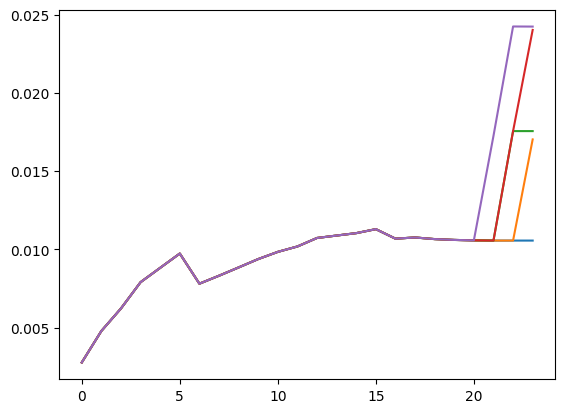

In [5]:
for a in arrayGrande:
    plt.plot(a)

plt.savefig("images/Search/LS_Poda/Balance_Ganado_{}.png".format(date.today()))

In [6]:
best_solution = resultado_mercado_secundario[0]
for solution in resultado_mercado_secundario:
    if best_solution.cumulative_price < solution.cumulative_price:
        best_solution = solution

In [7]:
actual = best_solution
soc = []
estado = []
while(True):

    soc.append(actual.agents_info["B1"]["soc"])
    estado.append(actual)
    if actual.day_step == 0:
        break
    actual = actual.father
estado.reverse()
soc.reverse()

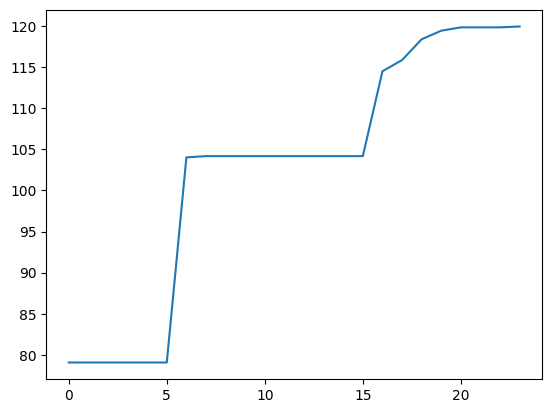

In [8]:
plt.plot(soc)
plt.show()

In [9]:
for i in estado:
    print(i)

{
    "consumption": 4.0634999999999994,
    "cumulative_consumption": 4.0634999999999994,
    "price": 0.00277524522,
    "cumulative_price": 0.00277524522,
    "_episode_ended": false,
    "day_step": 0,
    "actions": {
        "B1": 1
    },
    "agents_info": {
        "B1": {
            "soc": 79.0635,
            "chargeHistory": 4.0634999999999994,
            "dischargeHistory": 0
        }
    },
    "specific": {}
}
{
    "consumption": 0,
    "cumulative_consumption": 4.0634999999999994,
    "price": 0.0020128477049999997,
    "cumulative_price": 0.004788092924999999,
    "_episode_ended": false,
    "day_step": 1,
    "actions": {
        "B1": 0
    },
    "agents_info": {
        "B1": {
            "soc": 79.0635,
            "chargeHistory": 4.0634999999999994,
            "dischargeHistory": 0
        }
    },
    "specific": {}
}
{
    "consumption": 0,
    "cumulative_consumption": 4.0634999999999994,
    "price": 0.0014405554349999998,
    "cumulative_price": 0.00